Анализ потреления электроэнергии на заводе.
Цель: проанализировать электропотребление 3-х цехов завода за 2024 год.
Инструменты: python (pandas, matplotlib).
Результат: Выявлены аномалии в работе цехов №2, №3.

Шаг 1. Создаем "грязный" CSV 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1 Создаем сырые данные
np.random.seed(42) #Чтобы данные были одинаковые при каждом запуске
dates = pd.date_range(start='2024-01-01', periods=100, freq='D')
data={
    'date': dates,
    'workshop': np.random.choice(['Цех 1', 'Цех 2', 'Цех 3'],100),
    'consumption_kwh': np.random.normal(loc=500, scale=100, size=100) #Среднее 100 кВт*ч, разброс 100
}
df=pd.DataFrame(data)
# 2 создаем пропуски (связть от датчиков пропала)
df.loc[5:10,'consumption_kwh']=np.nan

# 3 добавим аномалии, отрицательное потребление (ошибка счетчика)
df.loc[20, 'consumption_kwh']=-50

# 4 добавим дубликат строки
df=pd.concat([df,df.iloc[[15]]], ignore_index=True)

# 5 сохраняем в CSV файл
df.to_csv('energy_data.csv', index=False)
print("Файл energy_data.CSV создан! Размер:", df.shape)


Файл energy_data.CSV создан! Размер: (101, 3)


Шаг 2. Читаем созданный файл

In [ ]:
import pandas as pd
# 1 читаем наш файл
df=pd.read_csv('energy_data.csv')

# 2 смотрим первые 5 строк
print("--- первые 5 строк ---")
print(df.head())

# 3 смотрим размер таблицы (строки, стобцы)
print("\nразмер таблицы:", df.shape)

---первые 5 строк---
         date workshop  consumption_kwh
0  2024-01-01    Цех 3       558.212279
1  2024-01-02    Цех 1       588.774846
2  2024-01-03    Цех 3       589.433233
3  2024-01-04    Цех 3       575.499780
4  2024-01-05    Цех 1       479.283411

размер таблицы: (101, 3)


Шаг 3. Очистка данных

In [10]:
# 1 Количество пропусков в данных
print("--- Пропусков в данных по колоннам ---")
print(df.isna().sum())

# 2 Посмотрим на аномалии (отрицательные значения)
print("\n--- Строка с отрицательным потреблением ---")
print(df[df['consumption_kwh']<0])

# 3 Заполняем пропуски в потреблении средним значением
mean_consumption = df['consumption_kwh'].mean()
df['consumption_kwh']=df['consumption_kwh'].fillna(mean_consumption)
print("\nПропуски заполнены, осталось NaN:",df['consumption_kwh'].isna().sum())

# 4 Удалим строку с отрицательным потреблением
df=df[df['consumption_kwh']>0]
print("\nТаблица после удаления аномалии:", df.shape)


--- Пропусков в данных по колоннам ---
date               0
workshop           0
consumption_kwh    6
dtype: int64

--- Строка с отрицательным потреблением ---
          date workshop  consumption_kwh
20  2024-01-21    Цех 1            -50.0

Пропуски заполнены, осталось NaN: 0

Таблица после удаления аномалии: (100, 3)


Шаг 4. Создаем сводную таблицу

In [ ]:
# 1 Изменение формата даты, чтобы вытащить месяцы
df['date']=pd.to_datetime(df['date'])
df['month']=df['date'].dt.month_name() # Название месяцев (january, february...)
# 2 Строим сводную таблицу: строки - цеха, колонки - месяцы, значения - сумма потребления
pivot=df.pivot_table(
    index='workshop',
    columns='month',
    values='consumption_kwh',
    aggfunc='sum',
    fill_value=0
)
print(pivot)

month           April     February      January        March
workshop                                                    
Цех 1     3959.708485  3845.211896  5097.612391  3984.889069
Цех 2        0.000000  4190.414543  4632.105439  9179.914367
Цех 3      964.093579  6143.717524  5964.121866  2643.463602


Шаг 5. Визуализация (диаграмма)

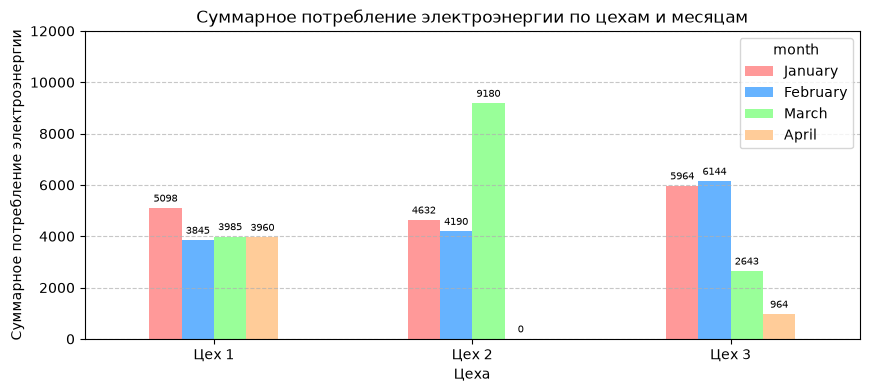

In [24]:
# 1 Представляем месяцы в правильном порядке
pivot=pivot[['January','February','March','April']]

# 2 Строим столбчатую диаграмму по сводной таблице
ax=pivot.plot(kind='bar', figsize=(10,4), color = ['#ff9999','#66b3ff','#99ff99','#ffcc99']) #Сохраняем как переменную ах

# 3 Добавляем подписи значений на столбцы диаграммы
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=7)
    #fmt='%,-f' отформатирование как чилсо без десятичных знаков
    #padding=3, отступ от верхушки стобца

# 4 Добавляем заголовок, подписи строк
plt.title('Суммарное потребление электроэнергии по цехам и месяцам')
plt.ylabel('Суммарное потребление электроэнергии')
plt.xlabel('Цеха')
plt.xticks(rotation=0) # названия горизонтально, как ось Х
plt.grid(axis='y',linestyle='--',alpha=0.7) # сетка по горизонтали
plt.ylim(0, 12000) #значение оси Y
plt.show()

1. Были проанализированы данные энергопотребления трех цехов по месяцам
2.  У цеха №1 энергопотребление по месяцам стабильно, находится в районе 3845-5100 кВт*ч.
У цеха №2 обнаружено аномально высокое потребление электроэнергии в марте (9180 кВт*ч). В апреле цех не работал.
У цеха №3 энергопотребление в январе, феврале стабильно (5964, 6144 кВт*ч). В марте снизилось до 2643 кВт*ч. В апреле снизилось до 964 кВт*ч.
3. Следует обратить внимание на цех №2 и цех №3.